### Dataset Overview: CFD Mixing Tank Suspension Quality
* **Source:** [Kaggle: Computational Fluid Dynamics : Mixing Tank](https://www.kaggle.com/datasets/comacque/computational-fluid-dynamics-mixing-tank) (based on ANSYS FLUENT RANS Euler-Granular CFD simulations, referenced on [ResearchGate](https://www.researchgate.net/publication/327059961_Solid-Liquid_Mixing_in_Stirred_Vessels_Numerical_Simulation_Experimental_Validation_and_Suspension_Quality_Prediction_Using_Multivariate_Regression_and_Machine_Learning)).
* **Objective:** Predict mixing quality (`Y`, a dimensionless number where lower values represent higher suspension quality) in a solid-liquid stirred vessel.
* **Features:** 78 normalized input variables (0 to 1), comprising 8 raw physical parameters (`X1`–`X8`: impeller design, stirring speed, tank diameter, particle size, fluid/solid densities, viscosity, and solid fraction) and 70 engineered features (`X9`–`X78`: dimensionless numbers and literature correlations).
* **Task Type:** Tabular Multivariate Regression evaluated on continuous numeric targets across 1,014 simulation instances.

**X1 : tank and agitator design \
X2 : stirring speed \
X3 : tank diameter \
X4 : solid particle diameter \
X5 : solid density\
X6 : fluid density \
X7 : fluid dynamic viscosity\
X8 : mean solid volume fraction.**

The Dataset Inputs (X2 to X8) are normalized between 0 and 1. \
**Y** is **RSD / 100 (RSD : Relative Standard Deviation**, which is the measure of extent of mixing). Y = 0 means complete mixing and the Y = 1 means poor mixing, stagnation zone exists.

In [87]:
import itertools

# Plotting & Visualization
import matplotlib.pyplot as plt
import numpy as np

# Data Manipulation & Math
import pandas as pd
from scipy.stats import norm
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)

# Machine Learning & Preprocessing
from sklearn.model_selection import KFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
import statsmodels.api as sm

# 1. Load data
df = pd.read_csv("kaggle-cfd-mixing-tank-selected-columns.csv")
print("Dataset Shape:", df.shape)
display(df.head())

Dataset Shape: (1014, 9)


,X1,X2,X3,X4,X5,X6,X7,X8,Y
0,Design 1,0.320113,0.034127,0.042394,0.068433,0.30303,0.469821,0.322034,0.019672
1,Design 1,0.320113,0.034127,0.142145,0.068433,0.30303,0.469821,0.322034,0.153489
2,Design 1,0.320113,0.034127,0.291771,0.068433,0.30303,0.469821,0.322034,0.279550
3,Design 1,0.320113,0.034127,0.441397,0.068433,0.30303,0.469821,0.322034,0.393393
4,Design 1,0.320113,0.034127,0.591022,0.068433,0.30303,0.469821,0.322034,0.475453


In [88]:
df.info()
display(df.describe())
print(df.isnull().sum())
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      1014 non-null   object 
 1   X2      1014 non-null   float64
 2   X3      1014 non-null   float64
 3   X4      1014 non-null   float64
 4   X5      1014 non-null   float64
 5   X6      1014 non-null   float64
 6   X7      1014 non-null   float64
 7   X8      1014 non-null   float64
 8   Y       1014 non-null   float64
dtypes: float64(8), object(1)
memory usage: 71.4+ KB


,X2,X3,X4,X5,X6,X7,X8,Y
count,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000,1014.000000
mean,0.131386,0.391933,0.249863,0.100199,0.227183,0.346694,0.352743,0.176841
std,0.131949,0.299606,0.262082,0.140020,0.188277,0.171936,0.199888,0.161374
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.034274,0.051835,0.082294,0.040994,0.127939,0.145987,0.237288,0.052156
50%,0.070343,0.356085,0.129676,0.061840,0.151515,0.429038,0.322034,0.128341
75%,0.192635,0.718690,0.384040,0.085886,0.172588,0.429038,0.457627,0.257741
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


X1    0
X2    0
X3    0
X4    0
X5    0
X6    0
X7    0
X8    0
Y     0
dtype: int64
['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'Y']


Hence, this dataset has **0 inputs missing**, and all the input variables X2 to X 8 are float. \
X1 is of type object and it contains the information of which design type it is.
Our dataset is already cleaned. \
The Machine Learning would be done for now, only on Design 1 because this is the design which has the maximum data available. However, this design was then tested on other designs, just to check if these model works.
Generally, the change in the design type: like the change of impeller, power number, aspect ratio, etc have severe impact on the physics. Whereas, the small changes AR for AR < 1 , Pitched angle, T etc shouldnt impact a lot.  

In [89]:
# Filter the dataframe to only include 'Design 1'
df_design1 = df[df["X1"] == "Design 1"]
print(f"Design 1 Samples: {len(df_design1)}")

# Use only the raw input features (X2 to X8) and target Y for Design 1
X = df_design1[["X2", "X3", "X4", "X5", "X6", "X7", "X8"]].values
y = df_design1["Y"].values

# 2. 75/25 Train-Test Split (matching the paper protocol on Design 1 only)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

Design 1 Samples: 534


The correlation matrix can help us to understand. \
Pearson correlation index as been utilized below, inorder to understand how different physical parameters (inputs) are related with Y; and also to check the relation between the input data.

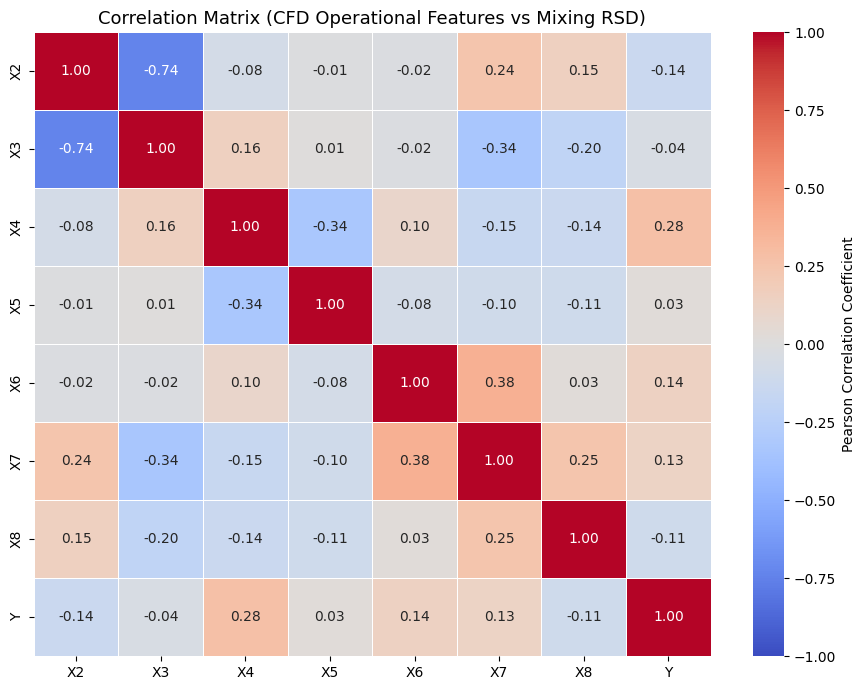


Correlation with target Y (sorted):
Y     1.000000
X4    0.276751
X6    0.142166
X7    0.129239
X5    0.030933
X3   -0.039884
X8   -0.108275
X2   -0.136420
Name: Y, dtype: float64


In [90]:
num_cols = ["X2", "X3", "X4", "X5", "X6", "X7", "X8", "Y"]
corr_matrix = df[num_cols].corr()

# Plot heatmap
plt.figure(figsize=(9, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "Pearson Correlation Coefficient"},
)
plt.title(
    "Correlation Matrix (CFD Operational Features vs Mixing RSD)", fontsize=13
)
plt.tight_layout()
plt.show()

print("\nCorrelation with target Y (sorted):")
print(corr_matrix["Y"].sort_values(ascending=False))

Based on this correlation matrix, it can be clearly seen that various input parameters were actually closely related. This could be because, during the CFD only one of the parameters were changed at a time. \
Based on the correlation with target Y, the pearson correlation is very low, for all the inputs. This might be because of the non-linear relation of inputs with the target (Relative Standard Deviation). However we still get the general idea on how the RSD gets affected by the input parameters say impeller speed, solid density etc.

**Linear Regression**

Even though the behaviour is tested to be highly non-linear, for the simplicity, the linear regression has been utilized here.

In [91]:
model_lr = LinearRegression()
model_lr.fit(X_train, y_train) # Fitted on Design 1 only
y_pred_lr = model_lr.predict(X_test)
# Train and Test Predictions
y_train_pred_lr = model_lr.predict(X_train)
y_pred_lr = model_lr.predict(X_test)

# Metrics
train_r2 = r2_score(y_train, y_train_pred_lr)
test_r2 = r2_score(y_test, y_pred_lr)
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_lr))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_lr))
test_mae = mean_absolute_error(y_test, y_pred_lr)

print("=" * 45)
print("       LINEAR REGRESSION PERFORMANCE         ")
print("=" * 45)
print(f"Train R²   : {train_r2:.4f}  | Train RMSE: {train_rmse:.4f}")
print(f"Test R²    : {test_r2:.4f}  | Test RMSE : {test_rmse:.4f}")
print(f"Test MAE   : {test_mae:.4f}")
print("=" * 45)

       LINEAR REGRESSION PERFORMANCE         
Train R²   : 0.2614  | Train RMSE: 0.1538
Test R²    : 0.0726  | Test RMSE : 0.1633
Test MAE   : 0.1251


The Linear Regression suffers from the severe underfitting. While the Train R2 value is around 0.26, the test R2 is 0.726.
This could be due to the fact that the physical parameters like Impeller speed have asymptote relation (approach constant RSD value, at speed > critical impeller speed). The Solid Volume Fraction exhibits the monotonic bell curve. Combined results of the fractional power dependencies, asymptotic behaviour and bell curve; the Linear Regression performs poorly. \
Based on the Results obtained : \
**Training error** is **very high** (since train r2 is very low). Thus, linear regression has **high bias**.

In [92]:
feature_names = ["X2", "X3", "X4", "X5", "X6", "X7", "X8"]

intercept = model_lr.intercept_
coefficients = model_lr.coef_

terms = [f"{coef:+.4f} * {feat}" for coef, feat in zip(coefficients, feature_names)]
equation = f"Y = {intercept:.4f} " + " ".join(terms)

print("Fitted Linear Regression Equation (Design 1 Only):")
print(equation)

Fitted Linear Regression Equation (Design 1 Only):
Y = 0.2089 -0.7554 * X2 -0.2382 * X3 +0.2466 * X4 +0.1939 * X5 +0.0213 * X6 +0.3142 * X7 -0.1450 * X8


**Physical Interpretation :** Y represents the relative standard devation of the solid phase concentration across the tank cells. Thus, lower RSD means better mixing. \
The physical parameters (Inputs) which show negative relation with Y are the one which positively favor the mixing. Ex: X2 is stirring speed which has the coefficient of **negative 0.7554**. Thus increase in X2 (stirring speed), has a **better mixing**. \
Similarly, the physical interpretations with other physical parameters can also be applied. \
Train and test r2 values have a **large gap**. Thus, Linear Regression also has a **high variance**, that is the model is sensitive to the data.

In [103]:
feature_names = ["X2", "X3", "X4", "X5", "X6", "X7", "X8"]
X_train_df = pd.DataFrame(X_train, columns=feature_names)

X_train_sm = sm.add_constant(X_train_df)
ols_model = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.261
Model:                            OLS   Adj. R-squared:                  0.248
Method:                 Least Squares   F-statistic:                     19.82
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           9.59e-23
Time:                        16:46:56   Log-Likelihood:                 181.37
No. Observations:                 400   AIC:                            -346.7
Df Residuals:                     392   BIC:                            -314.8
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.2089      0.048      4.345      0.0

In [104]:
# Forward Selection using Design 1 training data
feature_names = ["X2", "X3", "X4", "X5", "X6", "X7", "X8"]
X_tr_df = pd.DataFrame(X_train, columns=feature_names)
X_te_df = pd.DataFrame(X_test, columns=feature_names)

selected_features = []
remaining_features = list(feature_names)
history = []

for step in range(1, len(feature_names) + 1):
    best_aic = np.inf
    best_candidate = None
    best_res = None

    for candidate in remaining_features:
        trial_feats = selected_features + [candidate]
        X_design_mat = sm.add_constant(X_tr_df[trial_feats])
        res = sm.OLS(y_train, X_design_mat).fit()

        if res.aic < best_aic:
            best_aic = res.aic
            best_candidate = candidate
            best_res = res

    selected_features.append(best_candidate)
    remaining_features.remove(best_candidate)

    X_test_design = sm.add_constant(X_te_df[selected_features], has_constant="add")
    y_test_pred = best_res.predict(X_test_design)
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_rmse = np.sqrt(mean_squared_error(y_train, best_res.fittedvalues))

    history.append({
        "No_Params": step,
        "Feature_Added": best_candidate,
        "Features_Included": ", ".join(selected_features),
        "AIC": best_res.aic,
        "BIC": best_res.bic,
        "Train_RMSE": train_rmse,
        "Test_RMSE": test_rmse,
        "R2_Train": best_res.rsquared,
    })

selection_df = pd.DataFrame(history)
print("=== Model Complexity Table ===")
print(selection_df[["No_Params", "Feature_Added", "AIC", "BIC", "Test_RMSE", "R2_Train"]].to_string(index=False))

=== Model Complexity Table ===
 No_Params Feature_Added         AIC         BIC  Test_RMSE  R2_Train
         1            X7 -269.520691 -261.537762   0.168909  0.076872
         2            X4 -309.502526 -297.528132   0.166769  0.168848
         3            X8 -322.871965 -306.906106   0.169298  0.200178
         4            X5 -332.096082 -312.138759   0.164946  0.222309
         5            X2 -332.313920 -308.365133   0.163080  0.226609
         6            X3 -348.449459 -320.509208   0.163295  0.260891
         7            X6 -346.744297 -314.812581   0.163312  0.261435


The Above table helps us to understand the significance of the input parameters. Based on this, the **Minimum value of AIC and BIC** is for **No of params = 6**. \
Thus, X6 (fluid density is not significant for the prediction of Y, although it does help to improve the R2).  \
This conclusion could have been drawn from the model summary from the OLS regression results. p = 0.591 which implies that the 59.1 % times, the coefficient might be >= 0.0213

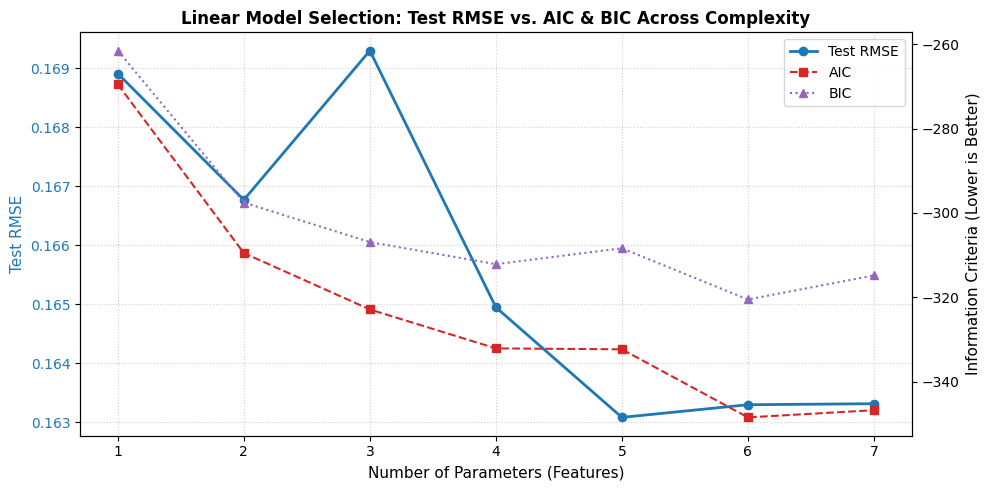

In [95]:
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Test RMSE on primary y-axis
color = "tab:blue"
ax1.set_xlabel("Number of Parameters (Features)", fontsize=11)
ax1.set_ylabel("Test RMSE", color=color, fontsize=11)
line1 = ax1.plot(
    selection_df["No_Params"],
    selection_df["Test_RMSE"],
    marker="o",
    color=color,
    linewidth=2,
    label="Test RMSE",
)
ax1.tick_params(axis="y", labelcolor=color)
ax1.grid(True, linestyle=":", alpha=0.6)

# Plot AIC & BIC on secondary y-axis
ax2 = ax1.twinx()
color2 = "tab:red"
color3 = "tab:purple"
ax2.set_ylabel("Information Criteria (Lower is Better)", fontsize=11)
line2 = ax2.plot(
    selection_df["No_Params"],
    selection_df["AIC"],
    marker="s",
    linestyle="--",
    color=color2,
    label="AIC",
)
line3 = ax2.plot(
    selection_df["No_Params"],
    selection_df["BIC"],
    marker="^",
    linestyle=":",
    color=color3,
    label="BIC",
)

# Combine legends
lines = line1 + line2 + line3
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="upper right")

plt.title(
    "Linear Model Selection: Test RMSE vs. AIC & BIC Across Complexity",
    fontsize=12,
    fontweight="bold",
)
plt.xticks(selection_df["No_Params"])
plt.tight_layout()
plt.show()

**SVR (Support Vector Regression)**

In [96]:
# Re-scale and train SVR on Design 1 only
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_svr = SVR(kernel="rbf", C=10.0, epsilon=0.01, gamma="scale")
model_svr.fit(X_train_scaled, y_train)
y_pred_svr = model_svr.predict(X_test_scaled)

y_train_pred_svr = model_svr.predict(X_train_scaled)
y_pred_svr = model_svr.predict(X_test_scaled)

# Metrics Calculation
train_r2_svr = r2_score(y_train, y_train_pred_svr)
test_r2_svr = r2_score(y_test, y_pred_svr)
train_rmse_svr = np.sqrt(mean_squared_error(y_train, y_train_pred_svr))
test_rmse_svr = np.sqrt(mean_squared_error(y_test, y_pred_svr))
test_mae_svr = mean_absolute_error(y_test, y_pred_svr)

print("=" * 45)
print("          SVR (RBF) PERFORMANCE              ")
print("=" * 45)
print(f"Train R²   : {train_r2_svr:.4f}  | Train RMSE: {train_rmse_svr:.4f}")
print(f"Test R²    : {test_r2_svr:.4f}  | Test RMSE : {test_rmse_svr:.4f}")
print(f"Test MAE   : {test_mae_svr:.4f}")
print("=" * 45)

          SVR (RBF) PERFORMANCE              
Train R²   : 0.9602  | Train RMSE: 0.0357
Test R²    : 0.7248  | Test RMSE : 0.0890
Test MAE   : 0.0583


**Physical Interpretation & Bias-Variance Analysis: SVR (RBF Kernel)**

The SVR model achieved an exceptional training fit ($R^2 = 0.9602$, $\text{RMSE} = 0.0357$), thus the Radial Basis Function kernel mapped the non-linearities of solid-liquid mixing effectively. \
The Bias is low, implying that the under-fitting is no longer an issue. \
The model still has a **moderate variance**, which implies that **mild overfitting** exists, since the change in R2 between the training and test datasets is 0.235.

The parity plots and error histogram are plotted in accordance with the reference papers Fig. 18 and Fig 20 for the Linear regression and the SVR respectively.

In [97]:
# 1. Convert test targets and predictions to physical RSD % (0 to 100%)
y_test_pct = y_test * 100.0
y_pred_lr_pct = y_pred_lr * 100.0
y_pred_svr_pct = y_pred_svr * 100.0


# 2. Shared plotting function for Parity & Error Histogram
def plot_evaluation(y_true, y_pred, title, color_scatter, color_hist):
    residuals = y_pred - y_true
    mu = np.mean(residuals)
    mae = np.mean(np.abs(residuals))
    sigma = np.std(residuals)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    # Parity Plot: Predicted vs Expected
    axes[0].scatter(y_true, y_pred, color=color_scatter, alpha=0.6, edgecolors="k")
    axes[0].plot([0, 100], [0, 100], "k--", lw=1.5, label="y = x")
    axes[0].set_xlabel("RSD (Expected) [%]", fontsize=11)
    axes[0].set_ylabel("RSD (Predicted) [%]", fontsize=11)
    axes[0].set_title(f"{title}: Parity Plot", fontsize=12)
    axes[0].set_xlim(0, 100)
    axes[0].set_ylim(0, 100)
    axes[0].grid(True, linestyle="--", alpha=0.5)
    axes[0].legend()

    # Residual Distribution + Gaussian Fit
    count, bins, _ = axes[1].hist(
        residuals,
        bins=30,
        density=True,
        color=color_hist,
        edgecolor="black",
        alpha=0.7,
    )
    x_axis = np.linspace(bins[0], bins[-1], 200)
    axes[1].plot(
        x_axis,
        norm.pdf(x_axis, mu, sigma),
        "r--",
        lw=2,
        label=rf"Fit: $\mu={mu:.2f}, \sigma={sigma:.2f}$",
    )
    axes[1].set_xlabel("Residual (Predicted - Expected) [%]", fontsize=11)
    axes[1].set_ylabel("Density", fontsize=11)
    axes[1].set_title(f"Error Histogram (MAE = {mae:.2f}%)", fontsize=12)
    axes[1].grid(True, linestyle="--", alpha=0.5)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

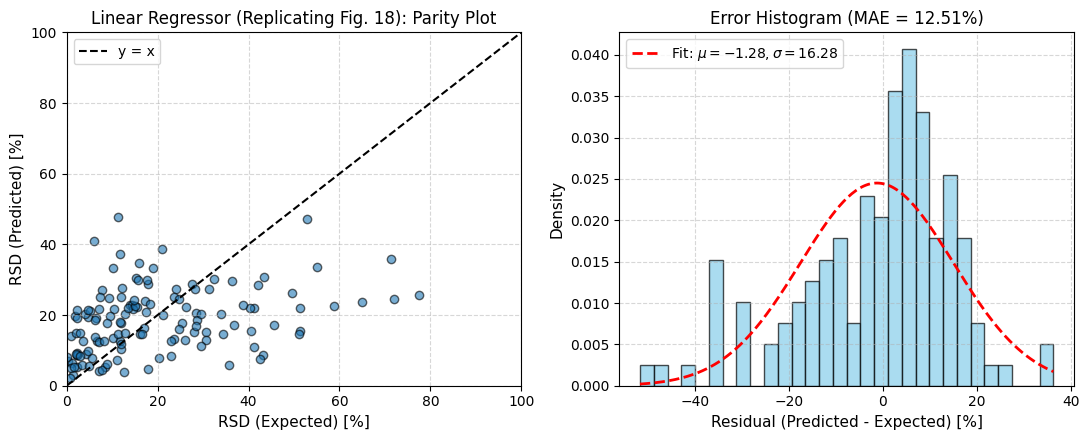

In [98]:
plot_evaluation(
    y_test_pct,
    y_pred_lr_pct,
    title="Linear Regressor (Replicating Fig. 18)",
    color_scatter="#1f77b4",
    color_hist="skyblue",
)

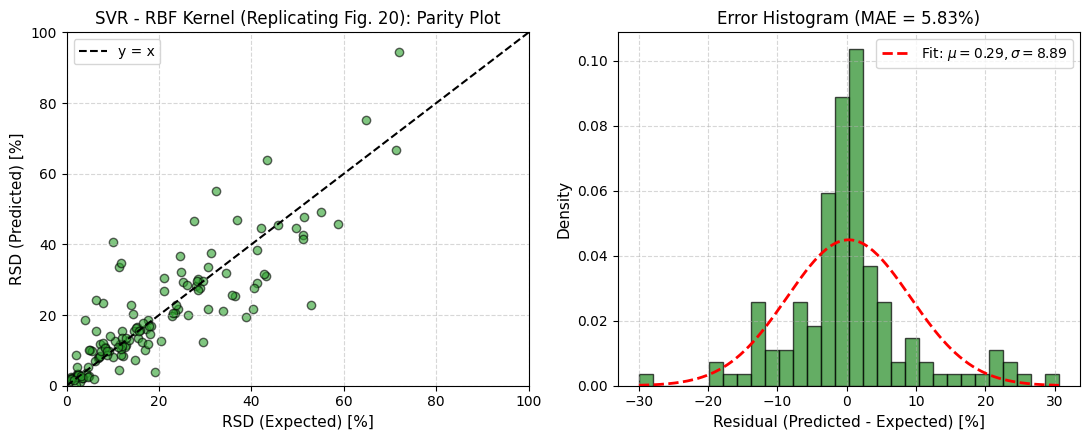

In [99]:
plot_evaluation(
    y_test_pct,
    y_pred_svr_pct,
    title="SVR - RBF Kernel (Replicating Fig. 20)",
    color_scatter="#2ca02c",
    color_hist="forestgreen",
)

**Model Evaluation: Linear Regressor (Baseline Benchmark)**
The parity plot shows large dispersion around the $y = x$ diagonal, failing to capture the steep non-linear relatio with inputs. The residual error distribution reveals a wide spread ($\text{MAE} \approx 12\% - 16\%$), confirming that an additive hyperplane suffers from severe structural underfitting (high bias) when predicting mixing RSD. \
**Model Evaluation: Support Vector Regressor (RBF Kernel)**
The parity plot demonstrates strong alignment along the ideal $y = x$ line across both low and high suspension regimes, effectively mapping the complex non-linearities. The residual error distribution is sharply centered near zero with an MAE of $\sim 5.8\%$, cutting the residual spread by more than half compared to the linear baseline.

Standard 5 fold Cross Validation Technique is performed, shuffling the indice and splits the target into 5 slices randomly. \
5 Fold CV helps us to understand the model stability, by checking the variance across different folds.

In [100]:
from sklearn.model_selection import KFold
import numpy as np
import pandas as pd

kf = KFold(n_splits=5, shuffle=True, random_state=42)

lr_rmse_list, lr_mae_list, lr_r2_list = [], [], []
svr_rmse_list, svr_mae_list, svr_r2_list = [], [], []

for fold, (train_idx, val_idx) in enumerate(kf.split(X), 1):
    X_tr, X_val = X[train_idx], X[val_idx]
    y_tr, y_val = y[train_idx], y[val_idx]

    # 1. Linear Regression (unscaled)
    lr = LinearRegression()
    lr.fit(X_tr, y_tr)
    y_pred_lr = lr.predict(X_val)

    lr_rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred_lr)))
    lr_mae_list.append(mean_absolute_error(y_val, y_pred_lr))
    lr_r2_list.append(r2_score(y_val, y_pred_lr))

    # 2. SVR (RBF Kernel - scaled inside the fold)
    fold_scaler = StandardScaler()
    X_tr_scaled = fold_scaler.fit_transform(X_tr)
    X_val_scaled = fold_scaler.transform(X_val)

    svr = SVR(kernel="rbf", C=10.0, epsilon=0.01, gamma="scale")
    svr.fit(X_tr_scaled, y_tr)
    y_pred_svr = svr.predict(X_val_scaled)

    svr_rmse_list.append(np.sqrt(mean_squared_error(y_val, y_pred_svr)))
    svr_mae_list.append(mean_absolute_error(y_val, y_pred_svr))
    svr_r2_list.append(r2_score(y_val, y_pred_svr))

cv_summary = pd.DataFrame({
    "Model": ["Linear Regression", "SVR (RBF Kernel)"],
    "Mean RMSE": [np.mean(lr_rmse_list), np.mean(svr_rmse_list)],
    "Std RMSE": [np.std(lr_rmse_list), np.std(svr_rmse_list)],
    "Mean MAE": [np.mean(lr_mae_list), np.mean(svr_mae_list)],
    "Std MAE": [np.std(lr_mae_list), np.std(svr_mae_list)],
    "Mean R²": [np.mean(lr_r2_list), np.mean(svr_r2_list)],
    "Std R²": [np.std(lr_r2_list), np.std(svr_r2_list)]
})

print("=== 5-Fold Cross-Validation Performance ===")
display(cv_summary.round(4))

=== 5-Fold Cross-Validation Performance ===


,Model,Mean RMSE,Std RMSE,Mean MAE,Std MAE,Mean R²,Std R²
0,Linear Regression,0.1591,0.0111,0.1244,0.0096,0.1740,0.0691
1,SVR (RBF Kernel),0.0905,0.0104,0.0574,0.0055,0.7204,0.0985


Thus, the single test set had the almpost same results as the 5 fold CV.

In general chemical and process engineering, a solid-liquid suspension is typically considered well-mixed (homogeneous) when the Relative Standard Deviation (**RSD**) of the solid concentration is ≤ **20%.**  
Thus, studying whether the model can predict accurately and with what precision, can help us to understand on the failure chances of the model.


========================= Linear Regression Classifier =========================
Accuracy  : 0.5896
Precision : 0.6892
Recall    : 0.6145
F1 Score  : 0.6497

Classification Report:
                    precision    recall  f1-score   support

Poor Mixing (>20%)       0.47      0.55      0.50        51
Well Mixed (<=20%)       0.69      0.61      0.65        83

          accuracy                           0.59       134
         macro avg       0.58      0.58      0.58       134
      weighted avg       0.60      0.59      0.59       134


========================= SVR (RBF Kernel) Classifier =========================
Accuracy  : 0.9104
Precision : 0.9383
Recall    : 0.9157
F1 Score  : 0.9268

Classification Report:
                    precision    recall  f1-score   support

Poor Mixing (>20%)       0.87      0.90      0.88        51
Well Mixed (<=20%)       0.94      0.92      0.93        83

          accuracy                           0.91       134
         macro avg       0.90   

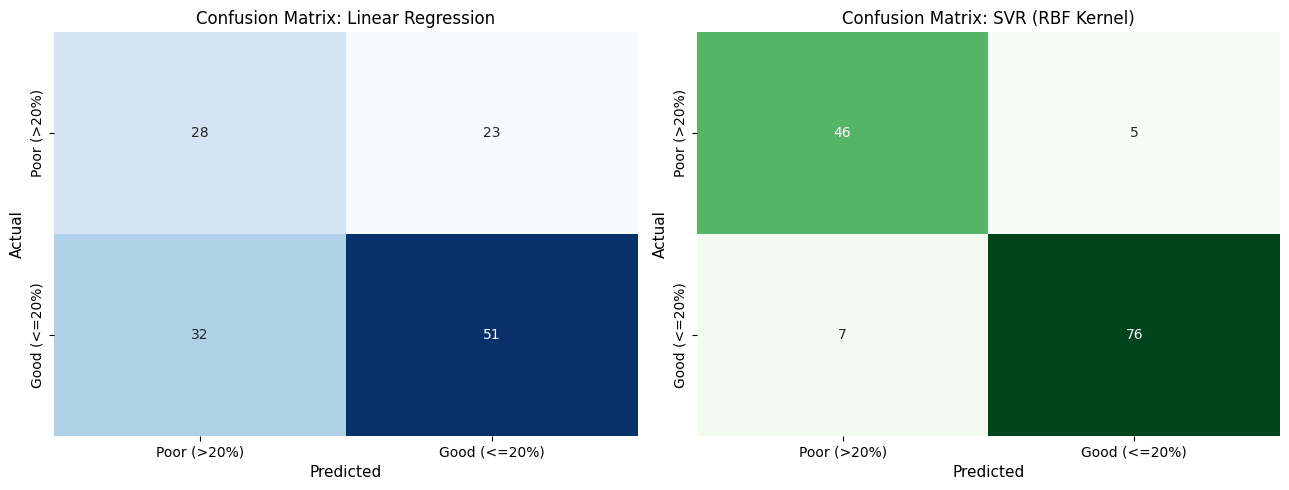

In [101]:
y_pred_lr = model_lr.predict(X_test)
y_pred_svr = model_svr.predict(X_test_scaled)

threshold = 20.0 if np.max(y_test) > 1.5 else 0.20

y_test_class = (y_test <= threshold).astype(int)
y_pred_lr_class = (y_pred_lr <= threshold).astype(int)
y_pred_svr_class = (y_pred_svr <= threshold).astype(int)


def print_classification_metrics(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    print(f"\n{'='*25} {model_name} {'='*25}")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1 Score  : {f1:.4f}")

    print("\nClassification Report:")
    print(
        classification_report(
            y_true,
            y_pred,
            target_names=["Poor Mixing (>20%)", "Well Mixed (<=20%)"],
            zero_division=0,
        )
    )

print_classification_metrics("Linear Regression Classifier", y_test_class, y_pred_lr_class)
print_classification_metrics("SVR (RBF Kernel) Classifier", y_test_class, y_pred_svr_class)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

labels = ["Poor (>20%)", "Good (<=20%)"]

# Linear Regression Confusion Matrix
cm_lr = confusion_matrix(y_test_class, y_pred_lr_class)
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[0],
)
axes[0].set_xlabel("Predicted", fontsize=11)
axes[0].set_ylabel("Actual", fontsize=11)
axes[0].set_title("Confusion Matrix: Linear Regression", fontsize=12)

# SVR Confusion Matrix
cm_svr = confusion_matrix(y_test_class, y_pred_svr_class)
sns.heatmap(
    cm_svr,
    annot=True,
    fmt="d",
    cmap="Greens",
    cbar=False,
    xticklabels=labels,
    yticklabels=labels,
    ax=axes[1],
)
axes[1].set_xlabel("Predicted", fontsize=11)
axes[1].set_ylabel("Actual", fontsize=11)
axes[1].set_title("Confusion Matrix: SVR (RBF Kernel)", fontsize=12)

plt.tight_layout()
plt.show()

Thus, Based on this, Linear Regression fails severely with 23 false positive (Type 1 error), whereas SVR reduces the failure to just 5.
SVR has an overall accuracy of **91.04 %**, Type 1 error (which causes operational failure) of just **5%**.

Since all the above study were done on the Design 1, the model trained on this design 1 has been tested on the other designs (Design 2 to Design 14) inorder to evaluate how they perform

In [102]:
feature_cols = ["X2", "X3", "X4", "X5", "X6", "X7", "X8"]

other_designs = sorted([d for d in df["X1"].unique() if d != "Design 1"])
design_eval_results = []

for d in other_designs + ["All Other Designs"]:
    if d == "All Other Designs":
        sub_df = df[df["X1"] != "Design 1"]
    else:
        sub_df = df[df["X1"] == d]

    X_test_d = sub_df[feature_cols].values
    y_test_d = sub_df["Y"].values

    # 1. Evaluate with pre-fitted model_lr (unscaled features)
    pred_lr = model_lr.predict(X_test_d)
    lr_rmse = np.sqrt(mean_squared_error(y_test_d, pred_lr))
    lr_mae = mean_absolute_error(y_test_d, pred_lr)
    lr_r2 = r2_score(y_test_d, pred_lr)

    # 2. Evaluate with pre-fitted model_svr (using pre-fitted scaler)
    X_test_d_scaled = scaler.transform(X_test_d)
    pred_svr = model_svr.predict(X_test_d_scaled)
    svr_rmse = np.sqrt(mean_squared_error(y_test_d, pred_svr))
    svr_mae = mean_absolute_error(y_test_d, pred_svr)
    svr_r2 = r2_score(y_test_d, pred_svr)

    design_eval_results.append({
        "Test Set": d,
        "Sample Count": len(sub_df),
        "LR RMSE": lr_rmse,
        "LR MAE": lr_mae,
        "LR R²": lr_r2,
        "SVR RMSE": svr_rmse,
        "SVR MAE": svr_mae,
        "SVR R²": svr_r2
    })

design_eval_df = pd.DataFrame(design_eval_results)
print("Using pre-fitted model_lr and model_svr trained on Design 1 (400 train samples)")
print("=== Generalization Across Tank & Agitator Designs ===")
display(design_eval_df.round(4))

Using pre-fitted model_lr and model_svr trained on Design 1 (400 train samples)
=== Generalization Across Tank & Agitator Designs ===


,Test Set,Sample Count,LR RMSE,LR MAE,LR R²,SVR RMSE,SVR MAE,SVR R²
0,Design 10,15,0.2480,0.2344,-0.4585,0.2065,0.1699,-0.0114
1,Design 11,8,0.1805,0.1519,-0.1780,0.1315,0.1103,0.3750
2,Design 12,7,0.1229,0.0950,0.4631,0.0208,0.0141,0.9847
3,Design 13,7,0.1387,0.1054,0.3770,0.0375,0.0297,0.9544
4,Design 14,7,0.1619,0.1209,0.1723,0.0724,0.0643,0.8344
5,Design 2,262,0.1226,0.0972,-0.2269,0.0939,0.0717,0.2802
6,Design 3,101,0.1439,0.1110,0.2669,0.1162,0.0907,0.5222
7,Design 4,19,0.0811,0.0633,0.4871,0.1068,0.0889,0.1089
8,Design 5,14,0.1340,0.1238,-1.4542,0.1223,0.0957,-1.0444
9,Design 6,7,0.1250,0.1149,-0.2457,0.1729,0.1514,-1.3857


It was observed that the Linear regression and SVR models fail on 7 and 5 designs respectively. This could be attributed to the fact that the difference in the models, would also have a different physical behavior. Ex. the channge of impeller from the pitched blade to the HydroFoil impeller can lead to a different behavior (due to significant reduction in power number Np)

**Comparison with the Reference Paper:**
In the reference study (Macqueron, 2020), SVR (RBF) showed only marginal improvement over the Linear Regressor (Validation RMSE of $0.0816$ vs. $0.0849$, Fig. 18 & 20) and exhibited a plateaued parity plot.
On the other hand, the model developed in this notebook shows that SVR performed significantly better than Linear Regression. This might be attributed to the fact that parameters used for training the SVR model are different.

The authors had developed a Neural Network to achieve higher precision—reducing the prediction error by an order of magnitude down to $\text{RMSE} \approx 0.006$ (Figures 29–30 [[1]](https://www.researchgate.net/publication/327059961_Solid-Liquid_Mixing_in_Stirred_Vessels_Numerical_Simulation_Experimental_Validation_and_Suspension_Quality_Prediction_Using_Multivariate_Regression_and_Machine_Learning)). \
Furthermore, as shown in Figure 31 ([[1]](https://www.researchgate.net/publication/327059961_Solid-Liquid_Mixing_in_Stirred_Vessels_Numerical_Simulation_Experimental_Validation_and_Suspension_Quality_Prediction_Using_Multivariate_Regression_and_Machine_Learning)), when trained on pooled data across all configurations, the Neural Network's high parameter capacity allows it to learn distinct geometric boundary regimes simultaneously, overcoming the severe design-dependency that causes SVR to fail on unseen geometries.